# DSA80003: Data Mining
**Group:** 4 

**Members:**

**Submission Date:** 26th November, 2026

### Import Libraries

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotnine
from pathlib import Path
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

## Data Collection

In [9]:
# 1. Define root path
data_dir = Path("UCI HAR Dataset")
dataset_url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

# 2. Check if dataset exists; if not, provide instructions or auto-download
if not data_dir.exists():
    print(f"Dataset folder '{data_dir}' not found locally.")
    print("Attempting to automatically download the UCI HAR dataset...")
    
    try:
        zip_path = Path("uci_har.zip")
        urllib.request.urlretrieve(dataset_url, zip_path)
        
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
            
        # The UCI zip contains a nested zip or folder structure sometimes, 
        # let's clean up the zip file
        zip_path.unlink()
        print("Dataset downloaded and extracted successfully!")
        
    except Exception as e:
        raise FileNotFoundError(
            f"Could not automatically download the dataset: {e}\n\n"
            f"Please download 'Human Activity Recognition Using Smartphones' manually from:\n"
            f"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones\n"
            f"Extract the 'UCI HAR Dataset' folder into your project root directory."
        )

# 3. Load features safely
features_file = data_dir / "features.txt"
if not features_file.exists():
    raise FileNotFoundError(f"Required file missing: {features_file}. Check your folder structure.")

features_df = pd.read_csv(features_file, sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

print(f"Successfully loaded {len(feature_names)} unique feature names.")

Successfully loaded 561 unique feature names.


### Split Dataset

In [10]:
import pandas as pd
from pathlib import Path

# 1. Define root path and load features ONCE (since they are shared between train and test)
data_dir = Path("UCI HAR Dataset")

features_df = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)


# 2. Create a reusable function for loading any split ('train' or 'test')
def load_har_split(split_name: str, data_dir: Path, feature_names: list) -> pd.DataFrame:
    """
    Loads and combines subject IDs, activity labels, and features 
    for a given dataset split ('train' or 'test').
    """
    split_dir = data_dir / split_name
    
    # Load individual components dynamically based on the split name
    X = pd.read_csv(split_dir / f"X_{split_name}.txt", sep=r"\s+", header=None, names=feature_names)
    y = pd.read_csv(split_dir / f"y_{split_name}.txt", sep=r"\s+", header=None, names=["activity_id"])
    subject = pd.read_csv(split_dir / f"subject_{split_name}.txt", sep=r"\s+", header=None, names=["subject_id"])
    
    # Combine everything into a single DataFrame
    df = pd.concat([subject, y, X], axis=1)
    
    return df


# 3. Load both train and test sets easily using the function
train_df = load_har_split("train", data_dir, feature_names)
test_df = load_har_split("test", data_dir, feature_names)

# Preview results
print(f"Train shape: {train_df.shape}")  # Should show (7352, 563)
print(f"Test shape:  {test_df.shape}")   # Should show (2947, 563)

Train shape: (7352, 563)
Test shape:  (2947, 563)


## Dataset Preprocessing

### Missingness Analysis

In [11]:
# 1. Check for missing values
train_missing = train_df.isnull().sum().sum()
test_missing = test_df.isnull().sum().sum()
print(f"Missing values -> Train: {train_missing} | Test: {test_missing}")

# 2. Check for duplicate rows
train_dups = train_df.duplicated().sum()
test_dups = test_df.duplicated().sum()
print(f"Duplicate rows -> Train: {train_dups} | Test: {test_dups}")

# 3. Inspect shapes and target distributions
print(f"\nTrain shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

Missing values -> Train: 0 | Test: 0
Duplicate rows -> Train: 0 | Test: 0

Train shape: (7352, 563)
Test shape:  (2947, 563)


Retrieve Feature Columns

### Apply standard scaling

Retain both the scaled and unscaled version

In [12]:
train_df

,subject_id,activity_id,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7347,30,2,0.299665,-0.057193,-0.181233,-0.195387,0.039905,0.077078,-0.282301,0.043616,...,-0.070157,-0.588433,-0.880324,-0.190437,0.829718,0.206972,-0.425619,-0.791883,0.238604,0.049819
7348,30,2,0.273853,-0.007749,-0.147468,-0.235309,0.004816,0.059280,-0.322552,-0.029456,...,0.165259,-0.390738,-0.680744,0.064907,0.875679,-0.879033,0.400219,-0.771840,0.252676,0.050053
7349,30,2,0.273387,-0.017011,-0.045022,-0.218218,-0.103822,0.274533,-0.304515,-0.098913,...,0.195034,0.025145,-0.304029,0.052806,-0.266724,0.864404,0.701169,-0.779133,0.249145,0.040811
7350,30,2,0.289654,-0.018843,-0.158281,-0.219139,-0.111412,0.268893,-0.310487,-0.068200,...,0.013865,0.063907,-0.344314,-0.101360,0.700740,0.936674,-0.589479,-0.785181,0.246432,0.025339


In [13]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Separate features from metadata
meta_cols = ["subject_id", "activity_id"]

X_train = train_df.drop(columns=meta_cols)
X_test = test_df.drop(columns=meta_cols)

# Preserve metadata separately
meta_train = train_df[meta_cols].copy()

# Initialize the scaler
scaler = StandardScaler()

# Fit on the training features and transform both train and test sets
# (Fitting strictly on train to prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames to preserve original 561 feature names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print(f"Scaled Training Shape: {X_train_scaled_df.shape}")
print(f"Scaled Testing Shape:  {X_test_scaled_df.shape}")

Scaled Training Shape: (7352, 561)
Scaled Testing Shape:  (2947, 561)


### Items to use for EDA

In [14]:
print(f"Unscaled Dataset: ", {X_train.shape})
print(f"Scaled dataset: ",{X_train_scaled.shape})
print(f"Subject ID, ", meta_train.shape)

Unscaled Dataset:  {(7352, 561)}
Scaled dataset:  {(7352, 561)}
Subject ID,  (7352, 2)


### Exploratory Data Analysis

Task 1 — Data quality and feature characteristics
Objective: Understand the quality and structure of the sensor measurements.

**Member**: Atharva

What needs to be done:

1. Check missing values, duplicates, constant features and extreme values.
2. Examine feature distributions and variance.
3. Identify highly correlated and redundant features.
4. Group features by their physical meaning: acceleration, gyroscope, gravity, jerk, time-domain and frequency-domain.
5. Examine how standardisation and duplicate-feature removal change feature distributions and relative weighting.

Expected output: A summary of data quality, feature redundancy and recommended preprocessing decisions.

In [15]:
# Code for EDA 1

Task 2 — Natural structure and movement relationships

Objective: Investigate whether the sensor data suggest meaningful movement groups and relationships.

**Member**: Abrar

What needs to be done:
1. Explore PCA projections of the sensor measurements.
2. Examine whether observations form distinct regions, overlapping distributions or continuous patterns.
3. Look for broad movement families and possible finer subdivisions.
4. Compare the apparent structure against known activity labels, using labels only for interpretation.
5. Investigate whether some activities occupy overlapping or nested regions of sensor space.
Expected output: Evidence describing the apparent organisation of movement and hypotheses about shared movement patterns.

At this stage, visual groupings are exploratory evidence, not validated clusters.


In [16]:
# Code for EDA 2


Task 3 — Physical interpretation of movement patterns
Objective: Understand which sensor characteristics distinguish or connect different movement patterns.

**Member**: Youssef

What needs to be done:
1. Explore acceleration, gyroscope and gravity-related feature distributions.
2. Compare time-domain and frequency-domain characteristics.
3. Identify which physical features differ most between activity groups.
4. Examine which activities share similar physical characteristics.
5. Investigate whether movement differences are associated with motion intensity, periodicity or orientation.
Expected output: Interpretable physical explanations for similarities and differences between movement patterns.



Training observations: 7,352 | Physical features: 561 | Modelling features: 561
Training set only; label names are used for interpretation, not for fitting anomaly models.

=== EDA TASK 3: PHYSICAL MOVEMENT PATTERNS ===
Physical feature availability: 7 of 7


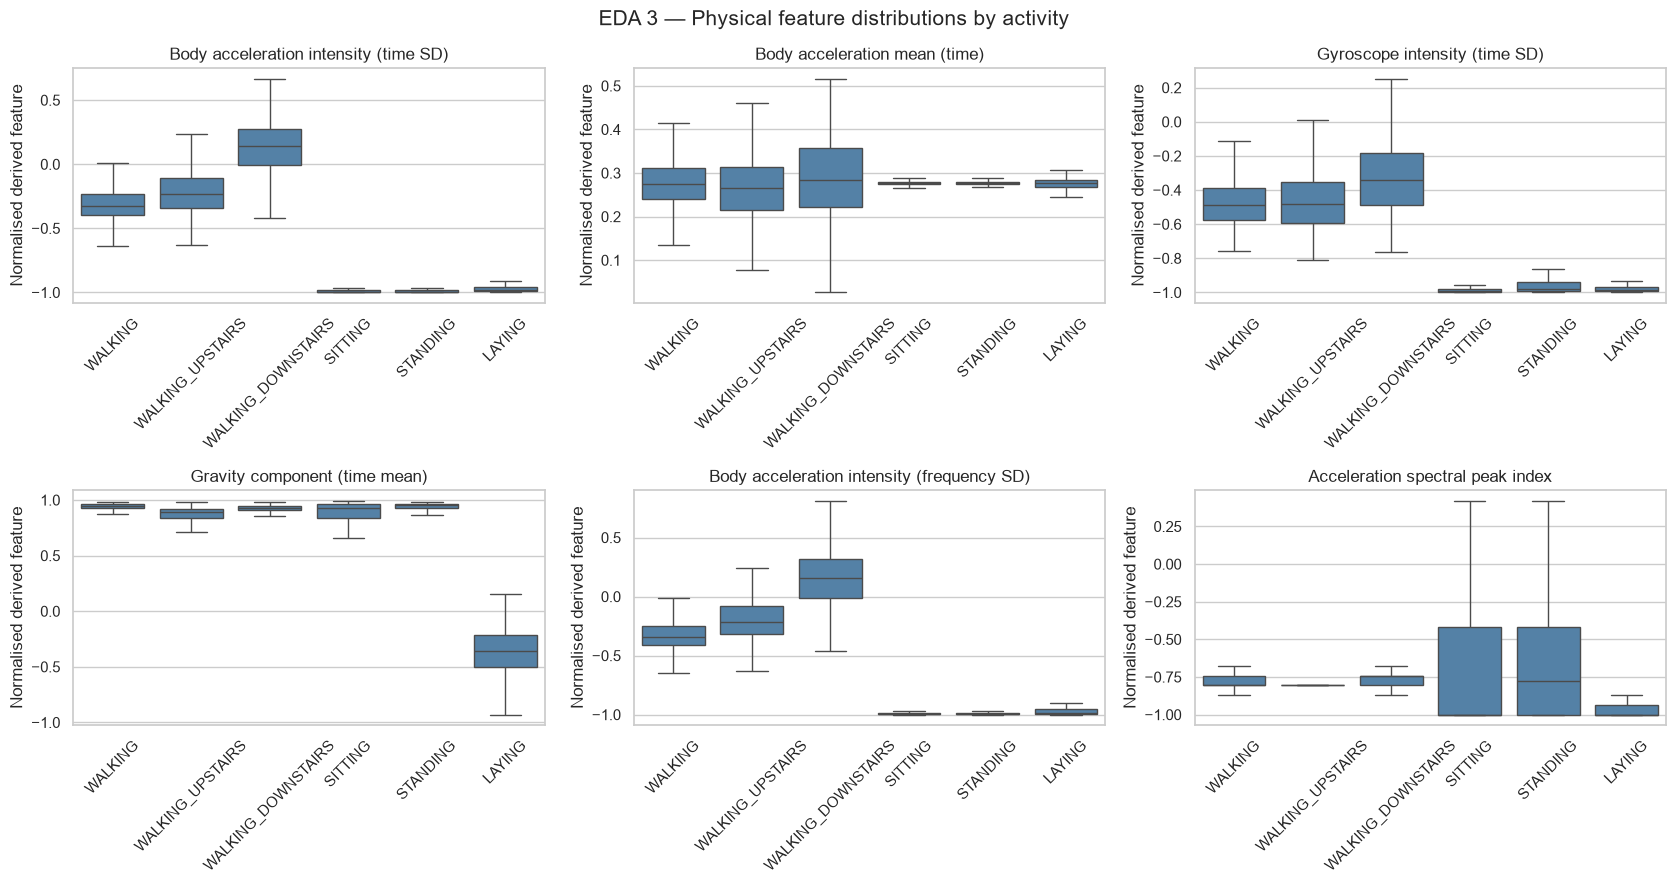


Top 12 features separating the six activities:
                      feature  eta_squared       sensor    domain
     fBodyAccJerk-entropy()-X        0.962 Acceleration Frequency
         tGravityAcc-mean()-X        0.952      Gravity      Time
          tGravityAcc-min()-X        0.950      Gravity      Time
     fBodyAccJerk-entropy()-Y        0.950 Acceleration Frequency
          tGravityAcc-max()-X        0.948      Gravity      Time
       tGravityAcc-energy()-X        0.946      Gravity      Time
fBodyBodyAccJerkMag-entropy()        0.941 Acceleration Frequency
    tBodyAccJerkMag-entropy()        0.941 Acceleration      Time
         fBodyAcc-entropy()-X        0.940 Acceleration Frequency
     tBodyAccJerk-entropy()-X        0.938 Acceleration      Time
             tBodyAcc-max()-X        0.932 Acceleration      Time
     fBodyAccJerk-entropy()-Z        0.928 Acceleration Frequency

Average separability by sensor and domain:
                         mean  count
sensor       

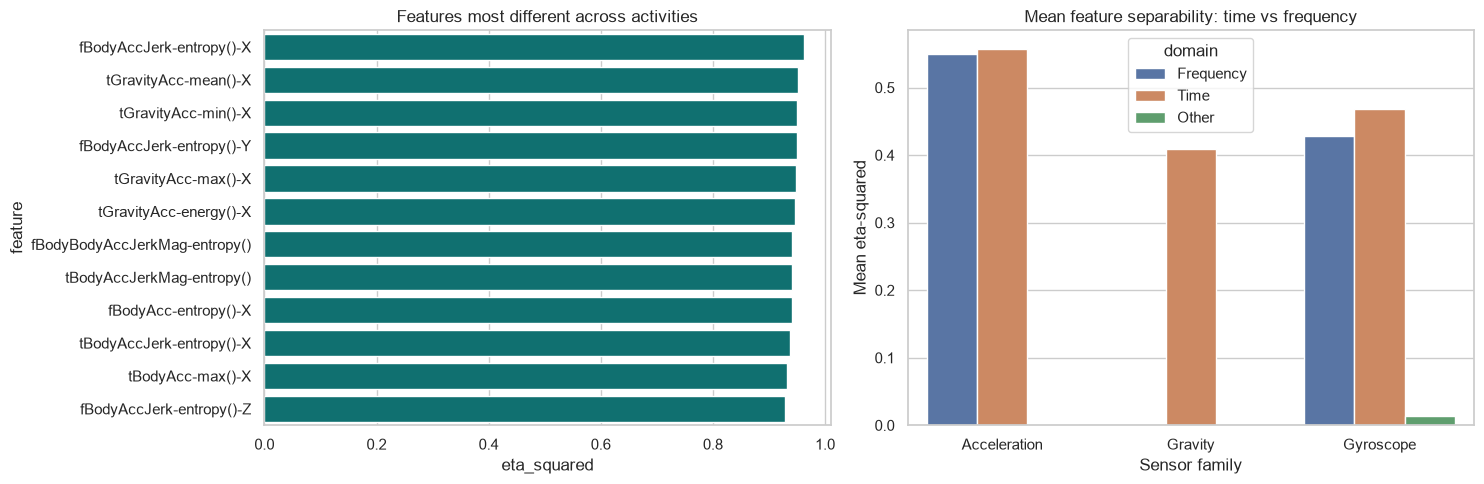


Closest activity pairs in standardised physical feature centroids:
  SITTING + STANDING: centroid distance 3.96
  SITTING + LAYING: centroid distance 7.62
  STANDING + LAYING: centroid distance 9.51
  WALKING + WALKING_UPSTAIRS: centroid distance 10.63
  WALKING + WALKING_DOWNSTAIRS: centroid distance 11.91


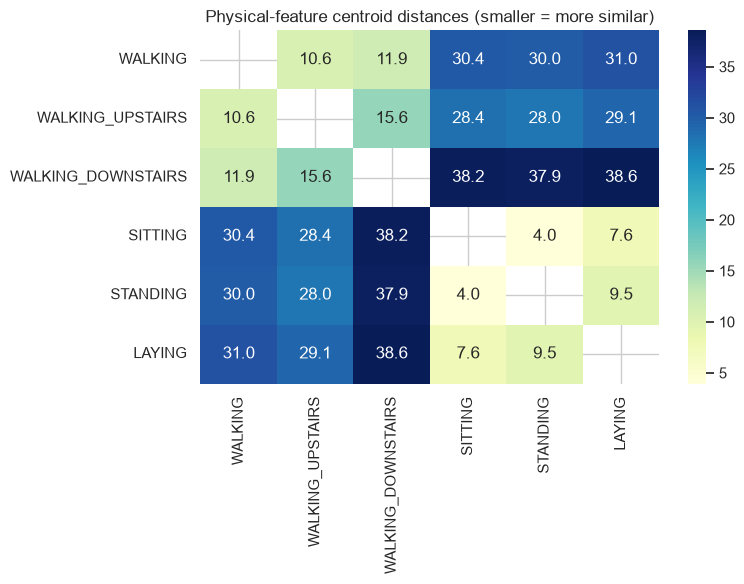


Motion intensity, spectral peak index, and gravity/orientation-related means:
                    tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyGyro-std()-X  tBodyGyro-std()-Y  tBodyGyro-std()-Z  fBodyAcc-maxInds-X  fBodyAcc-maxInds-Y  fBodyAcc-maxInds-Z  tGravityAcc-mean()-X  tGravityAcc-mean()-Y  tGravityAcc-mean()-Z
activity                                                                                                                                                                                                                                                       
WALKING                       -0.313            -0.020            -0.246             -0.461             -0.326             -0.321              -0.773              -0.693              -0.782                 0.933                -0.200                -0.065
WALKING_UPSTAIRS              -0.221            -0.000            -0.140             -0.461             -0.322             -0.238              -0.797    

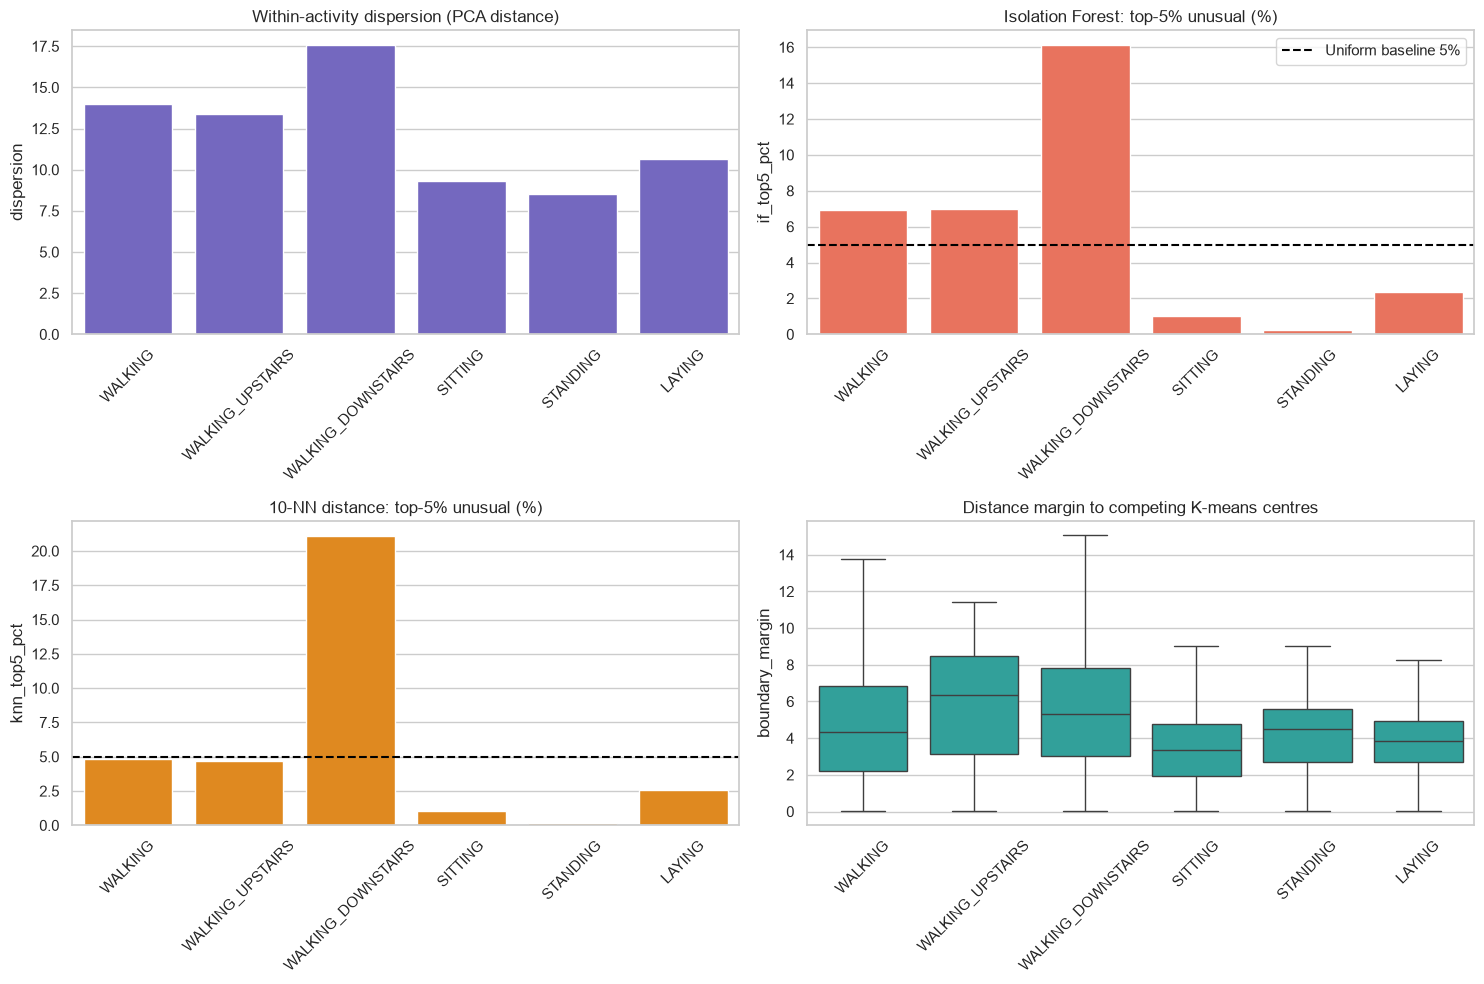


Across six activities: dispersion vs Isolation Forest top-5% rate:
Spearman rho=0.94, p=0.005
Agreement across methods: 279 windows appear in both top-5% shortlists

Boundary/density/dispersion comparison:
           median_boundary_margin  median_knn_distance  median_within_activity_dispersion
Other 95%                   4.260                7.461                             10.400
IF top 5%                   5.136               16.522                             27.981


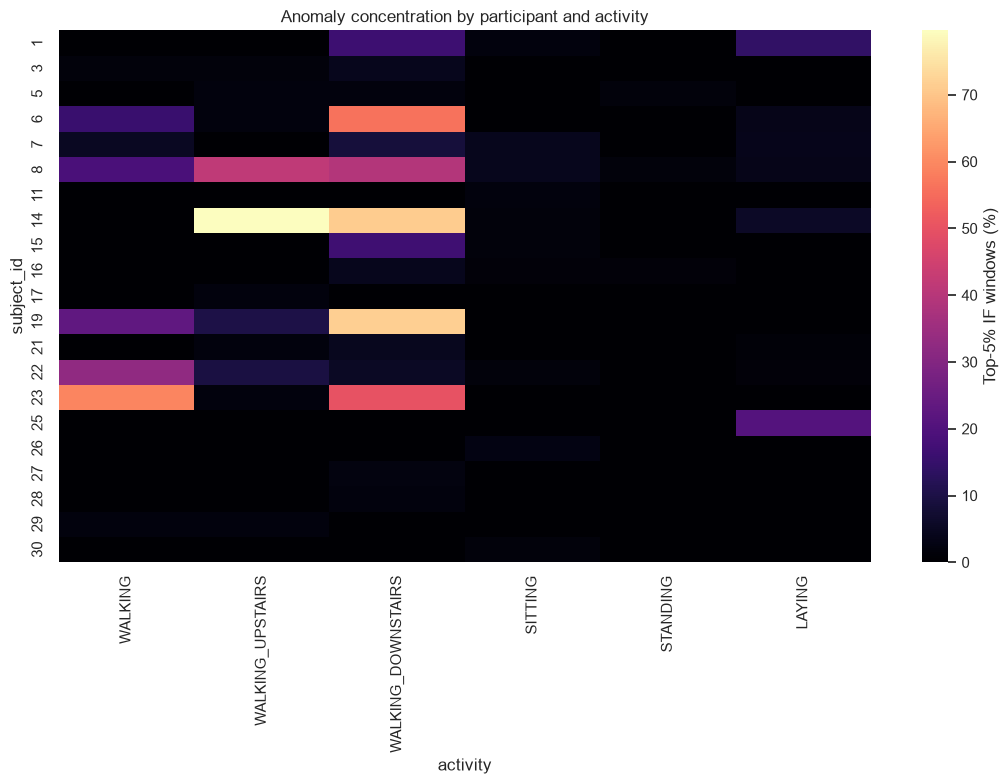


=== INTERPRETATION FOR REPORT ===
Largest within-activity dispersion: WALKING_DOWNSTAIRS.
Highest global Isolation Forest unusualness rate: WALKING_DOWNSTAIRS (16.1%; 3.2x uniform baseline).
Lowest unusualness rate: STANDING (0.2%).
Closest physical movement profiles: SITTING and STANDING.

Caution: These are unsupervised unusualness scores, NOT verified abnormal motions.
Overlapping 2.56-second windows, subject differences, correlated features and cluster geometry may influence rankings.
No transition labels are supplied.
For the shared RQ2 report, compare these patterns with the group's other clustering results.
Investigate flagged windows before attributing them to actual physical irregularities.

=== YOUSSEF ANALYSIS COMPLETED ===


In [18]:
# ================================================================
# YOUSSEF — EDA TASK 3 + RESEARCH QUESTION 2 (ONE NOTEBOOK CELL)
# Requires train_df from the notebook's data-loading cells.
# ================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
ACTIVITY_NAMES = {
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
}
ORDER = list(ACTIVITY_NAMES.values())

if "train_df" not in globals():
    raise RuntimeError(
        "Run the earlier notebook cells that create train_df first."
    )

if not {"activity_id", "subject_id"}.issubset(train_df.columns):
    raise ValueError(
        "train_df must contain activity_id and subject_id."
    )

d = train_df.copy().reset_index(drop=True)
d["activity"] = d["activity_id"].map(ACTIVITY_NAMES)

if d["activity"].isna().any():
    raise ValueError("Unexpected activity IDs found.")

feature_cols = [
    c for c in d.columns
    if c not in ("activity", "activity_id", "subject_id")
]

X = d[feature_cols].apply(pd.to_numeric, errors="raise")

# Remove constant features only for multivariate modelling.
model_cols = X.columns[X.std(ddof=0) > 1e-12]
Z = StandardScaler().fit_transform(X[model_cols])

print(
    f"Training observations: {len(d):,} | "
    f"Physical features: {len(feature_cols)} | "
    f"Modelling features: {len(model_cols)}"
)
print(
    "Training set only; label names are used for interpretation, "
    "not for fitting anomaly models.\n"
)

# ================================================================
# EDA TASK 3: PHYSICAL FEATURE INTERPRETATION
# ================================================================

# Dataset features are mostly normalised, not raw physical units.
physical_features = {
    "Body acceleration intensity (time SD)": "tBodyAcc-std()-X",
    "Body acceleration mean (time)": "tBodyAcc-mean()-X",
    "Gyroscope intensity (time SD)": "tBodyGyro-std()-X",
    "Gravity component (time mean)": "tGravityAcc-mean()-X",
    "Body acceleration intensity (frequency SD)": "fBodyAcc-std()-X",
    "Acceleration spectral peak index": "fBodyAcc-maxInds-X",
    "Gyroscope energy (frequency)": "fBodyGyro-energy()-X"
}

chosen = {
    label: col
    for label, col in physical_features.items()
    if col in X.columns
}

if len(chosen) < 4:
    raise ValueError(
        "Expected UCI HAR physical feature names were not found."
    )

print("=== EDA TASK 3: PHYSICAL MOVEMENT PATTERNS ===")
print(
    "Physical feature availability:",
    len(chosen),
    "of",
    len(physical_features)
)

# ------------------------------------------------
# 1. Physical feature distributions by activity
# ------------------------------------------------

view = list(chosen.items())[:6]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for ax, (label, col) in zip(axes.flat, view):
    sns.boxplot(
        data=d,
        x="activity",
        y=col,
        order=ORDER,
        ax=ax,
        showfliers=False,
        color="steelblue"
    )
    ax.set_title(label)
    ax.set(
        xlabel="",
        ylabel="Normalised derived feature"
    )
    ax.tick_params(axis="x", rotation=45)

for ax in axes.flat[len(view):]:
    ax.axis("off")

fig.suptitle(
    "EDA 3 — Physical feature distributions by activity",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 2. Feature separability by sensor and domain
# ------------------------------------------------

def eta_squared(frame, labels):
    grand_mean = frame.mean(axis=0)
    total_ss = ((frame - grand_mean) ** 2).sum(axis=0)

    between_ss = pd.Series(
        0.0,
        index=frame.columns
    )

    for activity in ORDER:
        mask = labels.eq(activity)

        if mask.sum():
            between_ss += (
                mask.sum()
                * (frame.loc[mask].mean(axis=0) - grand_mean) ** 2
            )

    return (
        between_ss / total_ss.replace(0, np.nan)
    ).fillna(0)


eta = eta_squared(
    X,
    d["activity"]
).sort_values(ascending=False)

feature_summary = pd.DataFrame({
    "feature": eta.index,
    "eta_squared": eta.values
})


def family(name):
    if "GravityAcc" in name:
        return "Gravity"
    if "Gyro" in name:
        return "Gyroscope"
    if "Acc" in name:
        return "Acceleration"
    return "Other"


feature_summary["sensor"] = (
    feature_summary["feature"].map(family)
)

feature_summary["domain"] = (
    feature_summary["feature"]
    .str[0]
    .map({"t": "Time", "f": "Frequency"})
    .fillna("Other")
)

print("\nTop 12 features separating the six activities:")
print(
    feature_summary.head(12).to_string(
        index=False,
        float_format=lambda v: f"{v:.3f}"
    )
)

print("\nAverage separability by sensor and domain:")
print(
    feature_summary
    .groupby(["sensor", "domain"])["eta_squared"]
    .agg(["mean", "count"])
    .round(3)
    .to_string()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=feature_summary.head(12),
    y="feature",
    x="eta_squared",
    ax=axes[0],
    color="teal"
)

axes[0].set_title(
    "Features most different across activities"
)

sns.barplot(
    data=feature_summary[
        feature_summary["sensor"] != "Other"
    ],
    x="sensor",
    y="eta_squared",
    hue="domain",
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title(
    "Mean feature separability: time vs frequency"
)
axes[1].set(
    xlabel="Sensor family",
    ylabel="Mean eta-squared"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 3. Physical similarity between activities
# FIXED: No read-only NumPy array modification
# ------------------------------------------------

physical_cols = [
    c for c in X.columns
    if ("Acc" in c or "Gyro" in c)
    and (c.startswith("t") or c.startswith("f"))
]

P = StandardScaler().fit_transform(
    X[physical_cols]
)

centroids = (
    pd.DataFrame(P, columns=physical_cols)
    .assign(activity=d["activity"])
    .groupby("activity")
    .mean()
    .reindex(ORDER)
)

distances = pd.DataFrame(
    pairwise_distances(
        centroids,
        metric="euclidean"
    ),
    index=ORDER,
    columns=ORDER
)

# FIX: Use pandas .loc to safely update the diagonal.
# This avoids the "underlying array is read-only" error.
for activity in ORDER:
    distances.loc[activity, activity] = np.nan

nearest_pairs = sorted(
    (distances.loc[a, b], a, b)
    for i, a in enumerate(ORDER)
    for b in ORDER[i + 1:]
)

print(
    "\nClosest activity pairs in standardised "
    "physical feature centroids:"
)

for distance, a, b in nearest_pairs[:5]:
    print(
        f"  {a} + {b}: "
        f"centroid distance {distance:.2f}"
    )

plt.figure(figsize=(8, 6))

sns.heatmap(
    distances,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title(
    "Physical-feature centroid distances "
    "(smaller = more similar)"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 4. Motion intensity, periodicity and orientation
# ------------------------------------------------

proxy_cols = [
    c for c in [
        "tBodyAcc-std()-X",
        "tBodyAcc-std()-Y",
        "tBodyAcc-std()-Z",
        "tBodyGyro-std()-X",
        "tBodyGyro-std()-Y",
        "tBodyGyro-std()-Z",
        "fBodyAcc-maxInds-X",
        "fBodyAcc-maxInds-Y",
        "fBodyAcc-maxInds-Z",
        "tGravityAcc-mean()-X",
        "tGravityAcc-mean()-Y",
        "tGravityAcc-mean()-Z"
    ]
    if c in X
]

proxy_means = (
    d.groupby("activity")[proxy_cols]
    .mean()
    .reindex(ORDER)
)

print(
    "\nMotion intensity, spectral peak index, "
    "and gravity/orientation-related means:"
)

print(
    proxy_means.round(3).to_string()
)

print(
    "\nNOTE: Gravity axis means suggest phone orientation, "
    "not a calibrated body pose."
)
print(
    "A spectral peak index alone does not establish "
    "motion periodicity.\n"
)

# ================================================================
# RESEARCH QUESTION 2: MOVEMENT VARIABILITY AND ANOMALIES
# ================================================================

print(
    "=== RESEARCH QUESTION 2: "
    "VARIABILITY AND ANOMALY PROFILES ==="
)

# ------------------------------------------------
# 5. Dimensionality reduction using PCA
# ------------------------------------------------

n_components = min(
    30,
    Z.shape[1],
    Z.shape[0] - 1
)

pca = PCA(
    n_components=n_components,
    random_state=RANDOM_STATE
)

Q = pca.fit_transform(Z)

print(
    f"PCA variance explained by {n_components} "
    f"components: "
    f"{pca.explained_variance_ratio_.sum():.1%}"
)

# ------------------------------------------------
# 6. Isolation Forest anomaly detection
# ------------------------------------------------

iso = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

iso.fit(Q)

# Larger scores indicate more unusual observations.
d["if_score"] = -iso.score_samples(Q)

# ------------------------------------------------
# 7. K-nearest neighbours anomaly scores
# ------------------------------------------------

nn = NearestNeighbors(
    n_neighbors=11,
    n_jobs=-1
).fit(Q)

knn_dist, _ = nn.kneighbors(Q)

# Distance to the tenth other nearest neighbour.
d["knn_score"] = knn_dist[:, 10]

# ------------------------------------------------
# 8. K-means cluster boundary analysis
# ------------------------------------------------

km = KMeans(
    n_clusters=6,
    n_init=10,
    random_state=RANDOM_STATE
).fit(Q)

cluster_d = km.transform(Q)

# Sort each observation's distances to cluster centres.
cluster_d.sort(axis=1)

# Small margins indicate competing nearby clusters.
d["boundary_margin"] = (
    cluster_d[:, 1] - cluster_d[:, 0]
)

# ------------------------------------------------
# 9. Within-activity variability
# ------------------------------------------------

# Labels are used only to describe activity dispersion.
act_centres = {
    a: Q[
        d["activity"].eq(a).to_numpy()
    ].mean(axis=0)
    for a in ORDER
}

d["within_activity_distance"] = np.array([
    np.linalg.norm(
        point - act_centres[act]
    )
    for point, act in zip(Q, d["activity"])
])

# ------------------------------------------------
# 10. Identify the top 5% most unusual observations
# ------------------------------------------------

threshold_if = d["if_score"].quantile(0.95)
threshold_knn = d["knn_score"].quantile(0.95)

d["if_top5"] = (
    d["if_score"] >= threshold_if
)

d["knn_top5"] = (
    d["knn_score"] >= threshold_knn
)

results = (
    d.groupby("activity", observed=True)
    .agg(
        n=("if_score", "size"),
        dispersion=(
            "within_activity_distance", "mean"
        ),
        if_mean=("if_score", "mean"),
        if_top5_pct=(
            "if_top5",
            lambda x: x.mean() * 100
        ),
        knn_top5_pct=(
            "knn_top5",
            lambda x: x.mean() * 100
        ),
        boundary_margin=(
            "boundary_margin", "median"
        )
    )
    .reindex(ORDER)
)

results["IF_enrichment_vs_5pct"] = (
    results["if_top5_pct"] / 5.0
)

print(
    "\nActivity-level findings "
    "(5% expected if unusualness were uniform):"
)

print(
    results.round(2).to_string()
)

# ------------------------------------------------
# 11. Variability and anomaly visualisations
# ------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10)
)

sns.barplot(
    x=results.index,
    y=results["dispersion"],
    ax=axes[0, 0],
    color="slateblue"
)

axes[0, 0].set_title(
    "Within-activity dispersion (PCA distance)"
)

sns.barplot(
    x=results.index,
    y=results["if_top5_pct"],
    ax=axes[0, 1],
    color="tomato"
)

axes[0, 1].axhline(
    5,
    ls="--",
    color="black",
    label="Uniform baseline 5%"
)

axes[0, 1].legend()

axes[0, 1].set_title(
    "Isolation Forest: top-5% unusual (%)"
)

sns.barplot(
    x=results.index,
    y=results["knn_top5_pct"],
    ax=axes[1, 0],
    color="darkorange"
)

axes[1, 0].axhline(
    5,
    ls="--",
    color="black"
)

axes[1, 0].set_title(
    "10-NN distance: top-5% unusual (%)"
)

sns.boxplot(
    data=d,
    x="activity",
    y="boundary_margin",
    order=ORDER,
    showfliers=False,
    ax=axes[1, 1],
    color="lightseagreen"
)

axes[1, 1].set_title(
    "Distance margin to competing K-means centres"
)

for ax in axes.flat:
    ax.tick_params(
        axis="x",
        rotation=45
    )
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 12. Correlation between variability and anomalies
# ------------------------------------------------

rho, pvalue = spearmanr(
    results["dispersion"],
    results["if_top5_pct"]
)

print(
    "\nAcross six activities: dispersion vs "
    "Isolation Forest top-5% rate:"
)
print(
    f"Spearman rho={rho:.2f}, p={pvalue:.3f}"
)

score_agreement = (
    d["if_top5"] & d["knn_top5"]
).sum()

print(
    f"Agreement across methods: {score_agreement} "
    "windows appear in both top-5% shortlists"
)

# ------------------------------------------------
# 13. Anomalies and cluster boundaries
# ------------------------------------------------

summary = (
    d.groupby("if_top5")
    .agg(
        median_boundary_margin=(
            "boundary_margin", "median"
        ),
        median_knn_distance=(
            "knn_score", "median"
        ),
        median_within_activity_dispersion=(
            "within_activity_distance", "median"
        )
    )
)

summary.index = [
    "Other 95%",
    "IF top 5%"
]

print(
    "\nBoundary/density/dispersion comparison:"
)

print(
    summary.round(3).to_string()
)

# ------------------------------------------------
# 14. Anomaly rates by participant and activity
# ------------------------------------------------

subject_rates = (
    d.pivot_table(
        index="subject_id",
        columns="activity",
        values="if_top5",
        aggfunc="mean"
    ) * 100
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    subject_rates.reindex(columns=ORDER),
    cmap="magma",
    vmin=0,
    cbar_kws={
        "label": "Top-5% IF windows (%)"
    }
)

plt.title(
    "Anomaly concentration by participant and activity"
)

plt.tight_layout()
plt.show()

# ================================================================
# 15. AUTOMATIC INTERPRETATION FOR THE REPORT
# ================================================================

most_variable = (
    results["dispersion"].idxmax()
)

most_flagged = (
    results["if_top5_pct"].idxmax()
)

least_flagged = (
    results["if_top5_pct"].idxmin()
)

print("\n=== INTERPRETATION FOR REPORT ===")

print(
    f"Largest within-activity dispersion: "
    f"{most_variable}."
)

print(
    f"Highest global Isolation Forest unusualness rate: "
    f"{most_flagged} "
    f"({results.loc[most_flagged, 'if_top5_pct']:.1f}%; "
    f"{results.loc[most_flagged, 'IF_enrichment_vs_5pct']:.1f}x "
    f"uniform baseline)."
)

print(
    f"Lowest unusualness rate: {least_flagged} "
    f"({results.loc[least_flagged, 'if_top5_pct']:.1f}%)."
)

print(
    f"Closest physical movement profiles: "
    f"{nearest_pairs[0][1]} and "
    f"{nearest_pairs[0][2]}."
)

print(
    "\nCaution: These are unsupervised unusualness scores, "
    "NOT verified abnormal motions."
)

print(
    "Overlapping 2.56-second windows, subject differences, "
    "correlated features and cluster geometry may "
    "influence rankings."
)

print(
    "No transition labels are supplied."
)

print(
    "For the shared RQ2 report, compare these patterns "
    "with the group's other clustering results."
)

print(
    "Investigate flagged windows before attributing "
    "them to actual physical irregularities."
)

print(
    "\n=== YOUSSEF ANALYSIS COMPLETED ==="
)


Task 4 — Movement variability and diversity
Objective: Determine whether some types of movement exhibit greater internal variation than others.

What needs to be done:
1. Compare within-activity feature variance and multivariate dispersion.
2. Examine local neighbourhood distances and density differences.
3. Investigate whether some activities contain several distinct movement patterns.
4. Determine whether activity variability is distributed across participants or concentrated in a few individuals.
5. Investigate why walking downstairs is disproportionately represented among the existing high-scoring unusual observations.
Expected output: Evidence identifying which movements are more heterogeneous and potential explanations for their apparent unusualness.

In [ ]:
# Code for EDA 5

Task 5 — Participant-specific movement characteristics
Objective: Investigate whether individuals exhibit consistent and distinguishable movement patterns.

**Member**: Sushanth

What needs to be done:
1. Compare participants while controlling for activity type.
2. Examine how participant-specific feature distributions differ.
3. Investigate whether some participants occupy distinct regions within the same activity.
4. Compare within-participant and between-participant variability.
5. Examine whether participant 19 is consistently distinctive or whether only a few observations are extreme.
Expected output: Evidence showing whether individual movement differences are systematic or concentrated in isolated observations.


In [ ]:
# Code for EDA 5

Task 6 — Preliminary anomaly characteristics and concentration
Objective: Investigate which observations appear unusual and whether they are isolated or associated with recurring patterns.

**Member**: Muhatasim

What needs to be done:
1. Reproduce baseline neighbourhood-distance anomaly scores.
2. Examine score distributions and identify high-scoring observations for inspection.
3. Analyse anomaly concentration across activities and participants, accounting for their different sample sizes.
4. Determine whether high-scoring observations have other similar unusual observations nearby.
5. Inspect selected raw inertial-signal windows to identify distinguishing signal characteristics.
6. Compare preliminary unusualness under global neighbourhoods and restricted neighbourhoods, without treating either as ground truth.
Expected output: A preliminary anomaly profile identifying the observations and patterns that warrant further investigation.

In [ ]:
# Code for EDA 6

## Research Questions

### Research Question 1
**Members**: Atharva & Abrar

**Main Research Question:** Does human movement naturally organise into distinct categories, or into broader families containing overlapping and more specialised movement patterns?

**Methodology:**
1.	Perform unsupervised clustering (e.g., K-Means, GMM) on the 561-feature space.
2.  Analyze the resulting cluster structures (evaluate whether they form distinct groups or hierarchical sub-clusters)
3.  Compare unsupervized cluster assignment directuly against the hierarchical sub-clusters)
4.  Analyze divergence between machine-discovered structures vs human labeled classes

**Sub-Questions & Focus:**

1. Are the clusters truly 6 distinct groups mirroring the activity labels?
2. Can a geometric hierarchy be discovered within the space (e.g., are walking flat and walking upstairs grouped closer together than sitting and standing)?
3. How clearly do static postures separate from dynamic movements?

In [ ]:
# Code for Question 1

### Research Question 2
**Members**: Youssef & Sushanth

**Main Research Question:** Are some forms of human movement inherently more variable than others, and does this diversity explain why they appear disproportionately unusual?

**Methodology:**
1.	Execute anomaly detection models (e.g., Isolation Forest, density-based outlier scoring) across the feature space.
2.	Map anomaly and outlier scores directly back against cluster boundaries and feature variance metrics.
3.	Analyze whether anomaly concentrations are isolated to specific activities or driven by high-variance physical regimes.

**Questions and Focus:**
1. Are high-intensity or dynamic activities (like walking downstairs) inherently more variable, causing them to trigger false anomaly flags?
2. Are anomalies uniformly distributed across all activities, or clustered heavily in specific movement transitions?
3. Do unusual scores reflect true physical irregularities or geometric boundary crowding?


In [ ]:
# Code for Question 2

### Research Question 3
**Members**: Muhatasim & Subhashini

**Main Research Question:** Do unusual movement observations represent consistent differences in how individuals move, or isolated departures from otherwise typical movement behaviour?

**Methodology:**
1.	Take the cluster assignments and anomaly shortlists generated in RQ1 and RQ2.
2.	Cross-tabulate these spatial outputs against the known subject ID metadata (the 30 participants).
3.	Evaluate whether outlier concentrations are driven by single individuals or shared across multiple subjects.
4.	Investigate how individual biometric walking styles interact with global unsupervised boundaries (leveraging the sequential nature of data per subject).

**Sub-questions and focus:**
1. Are the top anomalies dominated by a single eccentric participant (e.g., one subject's unique stride), or are they common instances experienced across many people?
2. Does the unsupervised space fracture by participant identity rather than activity class?
3. How does unmanaged inter-subject variance distort global anomaly detection?


In [ ]:
# Code for Question 3